# Mammalian Family Classification from COI-5P DNA Barcodes

**ISA 3 – AI Lab | Data Science and Data Engineering**  
**Students:** Prashant Naik (2607) and Karan Haldankar (2612)

## Project objective
Predict the **mammalian family** from a COI-5P DNA barcode sequence, then investigate individual false-positive and false-negative predictions.

### Important design decisions
- Keep **all family classes**, including families with very few records. Do not impose a minimum class-frequency cutoff.
- Use DNA-derived features as the primary model inputs. Do **not** use `genus`, `species`, `order`, `family`-related taxonomy, process IDs, or location as predictive features.
- Retain specimen/taxonomic metadata separately for later error investigation.
- Exact duplicate sequences must not be split between training and testing. Identical sequences with conflicting family labels are ambiguous and will be flagged and excluded from supervised modelling, while remaining in the audit table.
- A family represented by only one unique sequence cannot be evaluated on a held-out test set while also being present in training. Such families will remain in training and be explicitly reported as not independently testable.

This notebook is the first reproducible baseline. It reports the actual class distribution before modelling so rare-class limitations are visible.

## 1. Imports and configuration
Run this notebook from the folder containing the downloaded BOLD TSV, or update `DATA_PATH` below.

In [1]:
# If a package is missing, uncomment and run:
# %pip install pandas numpy scikit-learn matplotlib seaborn joblib

from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Change this if your TSV is stored elsewhere.
DATA_PATH = Path("DS-EBACMAMM.tsv")

# The BOLD export has many columns; load only those needed for the first phase.
REQUIRED_COLUMNS = [
    "processid", "sampleid", "family", "genus", "species",
    "nuc", "marker_code", "country/ocean", "province/state",
    "collection_date_start", "habitat", "identification",
]
print("Data file:", DATA_PATH.resolve())
print("File exists:", DATA_PATH.exists())


Data file: D:\MSC_AI\Fundamentals_Of_AI\Lab\mam_fam_class\DS-EBACMAMM.tsv
File exists: True


## 2. Load the BOLD dataset
The notebook checks the required fields and prints the dimensions. If the file is not found, update `DATA_PATH` to the location of the TSV.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Set DATA_PATH to the full path of your downloaded BOLD TSV."
    )

df = pd.read_csv(DATA_PATH, sep="\t", usecols=lambda c: c in REQUIRED_COLUMNS,
                 low_memory=False, dtype={"processid": "string"})
print("Rows:", len(df))
print("Columns loaded:", df.columns.tolist())
display(df.head(3))


Rows: 52263
Columns loaded: ['processid', 'sampleid', 'family', 'genus', 'species', 'identification', 'collection_date_start', 'country/ocean', 'province/state', 'habitat', 'nuc', 'marker_code']


,processid,sampleid,family,genus,species,identification,collection_date_start,country/ocean,province/state,habitat,nuc,marker_code
0,ABBID001-08,MZB M26934,Vespertilionidae,Kerivoula,Kerivoula krauensis,Kerivoula krauensis,NaN,Indonesia,Kalimantan Timur,NaN,ACCCTATATCTACTATTTGGTGCTTGAGCAGGCATAGTGGGAACCG...,COI-5P
1,ABBID032-09,B09_mw309,Erinaceidae,Echinosorex,Echinosorex gymnura,Echinosorex gymnura,2006-05-01,Indonesia,Kalimantan Tengah,NaN,AACTTATATATAATTTTTGGTGCTTGAGCCGGTATGGTAGGAACGT...,COI-5P
2,ABBID064-09,E05_wc41,Vespertilionidae,Kerivoula,Kerivoula krauensis,Kerivoula krauensis,NaN,Indonesia,Lampung,NaN,ACCCTATATCTACTATTTGGTGCTTGAGCAGGCATAGTGGGAACCG...,COI-5P


## 3. Select mammalian COI-5P records
We select rows where `marker_code` is exactly `COI-5P`, a family label is present, and a nucleotide sequence is available. **No family is removed based on its record count.**

In [3]:
df["marker_code"] = df["marker_code"].astype("string").str.strip()
df["family"] = df["family"].astype("string").str.strip()

coi = df[
    df["marker_code"].eq("COI-5P")
    & df["family"].notna()
    & df["family"].ne("")
    & df["nuc"].notna()
].copy()

print(f"Usable COI-5P records with family labels: {len(coi):,}")
print(f"Distinct family labels: {coi['family'].nunique():,}")
print(f"Distinct species labels (where supplied): {coi['species'].nunique(dropna=True):,}")


Usable COI-5P records with family labels: 39,678
Distinct family labels: 140
Distinct species labels (where supplied): 2,285


## 4. Clean and validate DNA sequences
For the first baseline, retain canonical DNA bases (`A`, `C`, `G`, `T`) and remove whitespace/gaps. Ambiguous bases are counted and flagged; records containing non-ACGT symbols are not used in the initial k-mer model, but are retained in the audit dataframe. This avoids silently treating ambiguous characters as ordinary nucleotides.

In [4]:
def clean_sequence(value):
    if pd.isna(value):
        return ""
    # Uppercase and remove spaces, line breaks and alignment gap characters.
    seq = re.sub(r"\\s+", "", str(value).upper())
    seq = seq.replace("-", "").replace(".", "")
    return seq

coi["sequence_raw"] = coi["nuc"].astype("string")
coi["sequence"] = coi["sequence_raw"].map(clean_sequence)
coi["sequence_length"] = coi["sequence"].str.len()
coi["ambiguous_base_count"] = coi["sequence"].str.count(r"[^ACGT]")
coi["is_acgt_only"] = coi["sequence"].str.fullmatch(r"[ACGT]+").fillna(False)

print("Records with only A/C/G/T:", int(coi["is_acgt_only"].sum()))
print("Records containing ambiguous/non-ACGT symbols:", int((~coi["is_acgt_only"]).sum()))
print("Sequence length summary:")
display(coi["sequence_length"].describe())

# This audit table keeps excluded rows and the reason they were not modelled.
coi["audit_status"] = np.where(coi["is_acgt_only"], "eligible_for_baseline", "ambiguous_or_invalid_sequence")
display(coi[["processid", "family", "marker_code", "sequence_length",
             "ambiguous_base_count", "audit_status"]].head())


Records with only A/C/G/T: 34707
Records containing ambiguous/non-ACGT symbols: 4971
Sequence length summary:


count    39678.000000
mean       725.732648
std        242.058081
min        164.000000
25%        657.000000
50%        657.000000
75%        657.000000
max       1566.000000
Name: sequence_length, dtype: float64

,processid,family,marker_code,sequence_length,ambiguous_base_count,audit_status
0,ABBID001-08,Vespertilionidae,COI-5P,657,0,eligible_for_baseline
1,ABBID032-09,Erinaceidae,COI-5P,657,0,eligible_for_baseline
2,ABBID064-09,Vespertilionidae,COI-5P,657,0,eligible_for_baseline
3,ABBID079-09,Tupaiidae,COI-5P,648,0,eligible_for_baseline
4,ABBM002-05,Vespertilionidae,COI-5P,657,1,ambiguous_or_invalid_sequence


## 5. Inspect all family classes
This is an important decision point. We keep every family, including singleton and very rare families. The plot uses a logarithmic scale so that small classes remain visible beside very large ones.

Number of represented families: 140
Families with 1 record: 14
Families with fewer than 5 records: 38
Families with fewer than 10 records: 57


,family,record_count
0,Phyllostomidae,7456
1,Cricetidae,4388
2,Vespertilionidae,3951
3,Muridae,2847
4,Soricidae,1672
...,...,...
135,Thylacomyidae,1
136,Notoryctidae,1
137,Eupleridae,1
138,Mystacinidae,1


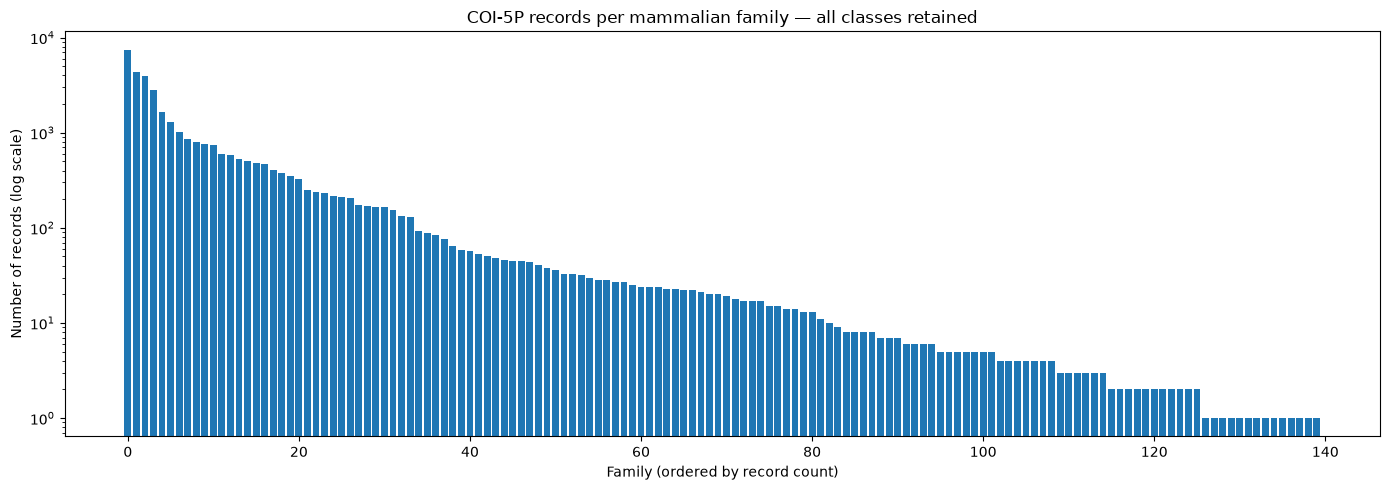

In [5]:
family_counts_all = (
    coi.loc[coi["is_acgt_only"], "family"]
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

print("Number of represented families:", len(family_counts_all))
print("Families with 1 record:", int((family_counts_all.record_count == 1).sum()))
print("Families with fewer than 5 records:", int((family_counts_all.record_count < 5).sum()))
print("Families with fewer than 10 records:", int((family_counts_all.record_count < 10).sum()))
display(family_counts_all)

plt.figure(figsize=(14, 5))
plt.bar(np.arange(len(family_counts_all)), family_counts_all["record_count"])
plt.yscale("log")
plt.xlabel("Family (ordered by record count)")
plt.ylabel("Number of records (log scale)")
plt.title("COI-5P records per mammalian family — all classes retained")
plt.tight_layout()
plt.show()


## 6. Check exact duplicate sequences and conflicting labels
Repeated records with the same sequence and same family can inflate performance if copies enter both splits. We therefore model one row per unique sequence. If an identical sequence has more than one family label, its label is ambiguous; we exclude that sequence from supervised training/testing but keep all source records in `coi` for investigation.

In [6]:
eligible = coi.loc[coi["is_acgt_only"]].copy()
eligible["sequence"] = eligible["sequence"].astype(str)

seq_family_counts = eligible.groupby("sequence")["family"].nunique()
conflicting_sequences = set(seq_family_counts[seq_family_counts > 1].index)

print("Eligible source records:", len(eligible))
print("Unique sequences:", eligible["sequence"].nunique())
print("Repeated source records beyond first copy:",
      len(eligible) - eligible["sequence"].nunique())
print("Unique sequences associated with conflicting family labels:",
      len(conflicting_sequences))

# Keep one representative per unique sequence only when its family label is unambiguous.
unambiguous = eligible.loc[~eligible["sequence"].isin(conflicting_sequences)].copy()
model_df = (
    unambiguous.sort_values("processid", na_position="last")
    .drop_duplicates(subset=["sequence"], keep="first")
    .reset_index(drop=True)
)

print("Unique, unambiguous sequences for baseline modelling:", len(model_df))
print("Families remaining in model table:", model_df["family"].nunique())
print("Families represented in eligible records but absent after conflict filtering:",
      sorted(set(eligible["family"]) - set(model_df["family"])))


Eligible source records: 34707
Unique sequences: 17313
Repeated source records beyond first copy: 17394
Unique sequences associated with conflicting family labels: 4
Unique, unambiguous sequences for baseline modelling: 17309
Families remaining in model table: 140
Families represented in eligible records but absent after conflict filtering: []


## 7. Create a duplicate-safe split while retaining all possible classes
We split **unique sequences within each family**. Every family with at least two unique sequences gets at least one sequence in train and one in test. A family with only one unique sequence stays in training because it is mathematically impossible to place that one sequence in both sets. Such a family is retained, but its generalisation performance cannot be measured from this single record.

This split prevents exact sequence duplicates from leaking across train and test. It does not guarantee that closely related sequences or records from the same species are separated; a stricter species-grouped evaluation can be added after the baseline.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
train_indices, test_indices = [], []
not_testable_families = []

for family, group in model_df.groupby("family", sort=True):
    idx = group.index.to_numpy(copy=True)
    rng.shuffle(idx)
    n = len(idx)
    if n == 1:
        train_indices.extend(idx.tolist())
        not_testable_families.append(family)
    else:
        n_test = max(1, int(round(n * TEST_SIZE)))
        n_test = min(n_test, n - 1)  # always leave at least one training example
        test_indices.extend(idx[:n_test].tolist())
        train_indices.extend(idx[n_test:].tolist())

train_df = model_df.loc[train_indices].sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
test_df = model_df.loc[test_indices].sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

train_families = set(train_df["family"])
test_families = set(test_df["family"])
print("Train sequences:", len(train_df))
print("Test sequences:", len(test_df))
print("Families in training:", len(train_families))
print("Families represented in test:", len(test_families))
print("Families not independently testable (one unique sequence):", len(not_testable_families))
print(sorted(not_testable_families))

assert train_families == set(model_df["family"]), "A family is missing from training."
assert set(train_df["sequence"]).isdisjoint(set(test_df["sequence"])), "Exact sequence leakage detected."
display(pd.DataFrame({
    "train_count": train_df["family"].value_counts(),
    "test_count": test_df["family"].value_counts()
}).fillna(0).astype(int).sort_index())


Train sequences: 13838
Test sequences: 3471
Families in training: 140
Families represented in test: 126
Families not independently testable (one unique sequence): 14
['Chinchillidae', 'Chlamyphoridae', 'Eupleridae', 'Mammutidae', 'Megaladapidae', 'Mystacinidae', 'Notoryctidae', 'Ornithorhynchidae', 'Paleopropithecidae', 'Platanistidae', 'Pseudocheiridae', 'Rhinopomatidae', 'Tarsipedidae', 'Thylacomyidae']


,train_count,test_count
family,,
Acrobatidae,1,1
Ailuridae,3,1
Anomaluridae,1,1
Antilocapridae,2,1
Aotidae,6,1
...,...,...
Ursidae,77,19
Vespertilionidae,1987,497
Viverridae,24,6


## 8. Extract DNA k-mer features
A k-mer is a consecutive substring of length *k*. For example, `ATGCTA` produces 4-mers `ATGC`, `TGCT`, and `GCTA`. We use a character n-gram count vectorizer with `k=4` as the initial baseline. The vectorizer is fitted on training data only.

In [8]:
KMER_SIZE = 4

vectorizer = CountVectorizer(
    analyzer="char",
    ngram_range=(KMER_SIZE, KMER_SIZE),
    lowercase=False,
    dtype=np.float32
)

X_train = vectorizer.fit_transform(train_df["sequence"])
X_test = vectorizer.transform(test_df["sequence"])
y_train = train_df["family"].to_numpy()
y_test = test_df["family"].to_numpy()

print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)
print("Number of observed k-mer features:", len(vectorizer.get_feature_names_out()))
print("Training samples:", X_train.shape[0])
print("Number of k-mer features:", X_train.shape[1])
print("Test samples:", X_test.shape[0])
print("Number of classes:", len(np.unique(y_train)))
print("Feature matrix type:", type(X_train))


Training feature matrix: (13838, 256)
Testing feature matrix: (3471, 256)
Number of observed k-mer features: 256
Training samples: 13838
Number of k-mer features: 256
Test samples: 3471
Number of classes: 140
Feature matrix type: <class 'scipy.sparse._csr.csr_matrix'>


## 9. Train baseline classifiers
We compare three models initially: Multinomial Naive Bayes, Logistic Regression, and Linear SVM. We use class weighting for Logistic Regression and Linear SVM to reduce the tendency to ignore smaller classes. Naive Bayes does not provide the same `class_weight` option. Hyperparameter tuning will be a later step.

In [9]:
models = {
    # 1. Probabilistic model
    "Multinomial Naive Bayes": MultinomialNB(
        alpha=0.5
    ),

    # 2. Linear models
    "Logistic Regression": LogisticRegression(
        max_iter=500,
        class_weight="balanced",
        solver="saga",
        tol=1e-3,
        random_state=RANDOM_STATE
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    
    # 3. Decision Tree
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    # 4. Random Forest
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        max_features="sqrt",
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

fitted_models = {}
predictions = {}
results = []

for name, model in models.items():
    print(f"Training {name} ...")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = pred

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, pred, average="macro", zero_division=0
    )
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    })

results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False)
display(results_df)


Training Multinomial Naive Bayes ...
Training Logistic Regression ...
Training Linear SVM ...
Training Decision Tree ...
Training Random Forest ...


,model,accuracy,macro_precision,macro_recall,macro_f1
1,Logistic Regression,0.962835,0.855935,0.874318,0.861629
2,Linear SVM,0.985595,0.858648,0.861004,0.855689
0,Multinomial Naive Bayes,0.885336,0.781389,0.813104,0.780013
4,Random Forest,0.953328,0.677967,0.692639,0.676359
3,Decision Tree,0.869778,0.560253,0.553871,0.541076


## 10. Evaluate one selected model
Choose a model by validation performance, preferably considering macro-F1 rather than accuracy alone because the family distribution is imbalanced. The test set is used here as a held-out evaluation set; avoid repeatedly tuning decisions against it.

In [10]:
BEST_MODEL_NAME = results_df.iloc[0]["model"]
best_model = fitted_models[BEST_MODEL_NAME]
best_predictions = predictions[BEST_MODEL_NAME]

print("Selected baseline:", BEST_MODEL_NAME)
print(classification_report(
    y_test, best_predictions,
    labels=sorted(model_df["family"].unique()),
    zero_division=0
))


Selected baseline: Logistic Regression
                    precision    recall  f1-score   support

       Acrobatidae       0.00      0.00      0.00         1
         Ailuridae       1.00      1.00      1.00         1
      Anomaluridae       0.00      0.00      0.00         1
    Antilocapridae       1.00      1.00      1.00         1
           Aotidae       1.00      1.00      1.00         1
          Atelidae       1.00      1.00      1.00         2
        Balaenidae       1.00      1.00      1.00         2
   Balaenopteridae       0.92      1.00      0.96        12
      Bathyergidae       1.00      1.00      1.00         1
           Bovidae       0.99      1.00      1.00       140
      Bradypodidae       1.00      1.00      1.00         3
       Burramyidae       1.00      1.00      1.00         1
     Caenolestidae       1.00      1.00      1.00         1
      Calomyscidae       1.00      1.00      1.00         9
         Camelidae       1.00      1.00      1.00         5


## 11. Build a record-level prediction and error table
The model is trained on unique sequences. We attach the original BOLD record identifiers and metadata to predictions so individual errors can be investigated later. The table distinguishes the actual family, predicted family, and correctness. Per-family TP/FP/FN/TN are computed in a one-vs-rest manner.

In [11]:
prediction_table = test_df[[
    "processid", "sampleid", "family", "genus", "species",
    "country/ocean", "province/state", "collection_date_start",
    "habitat", "sequence", "sequence_length", "ambiguous_base_count"
]].copy()

prediction_table = prediction_table.rename(columns={"family": "actual_family"})
prediction_table["predicted_family"] = best_predictions
prediction_table["correct"] = (
    prediction_table["actual_family"] == prediction_table["predicted_family"]
)
prediction_table["error_type_overall"] = np.where(
    prediction_table["correct"], "correct", "misclassified"
)

fp_fn_records = prediction_table.loc[~prediction_table["correct"]].copy()
print("Test records:", len(prediction_table))
print("Correct:", int(prediction_table["correct"].sum()))
print("Misclassified:", len(fp_fn_records))
display(fp_fn_records.head(10))


Test records: 3471
Correct: 3342
Misclassified: 129


,processid,sampleid,actual_family,genus,species,country/ocean,province/state,collection_date_start,habitat,sequence,sequence_length,ambiguous_base_count,predicted_family,correct,error_type_overall
10,ABCMA449-06,ROM MAM 115042,Vespertilionidae,Kerivoula,Kerivoula cf. hardwickii,China,Hunan,2002-09-09,NaN,ACTCTGTACTTGTTATTTGGTGCTTGAGCCGGCATGGTAGGAACCG...,657,0,Sciuridae,False,misclassified
34,BCBN572-05,ROM 104024,Phyllostomidae,Anoura,Anoura caudifer,Ecuador,Napo,1995-01-08,NaN,ACTCTGTACTTACTATTCGGCGCCTGAGCTGGCATAGTAGGTACCG...,657,0,Vespertilionidae,False,misclassified
38,GBMA7317-13,JX962118,Cricetidae,Cricetulus,Cricetulus longicaudatus,NaN,NaN,NaN,NaN,ACTAATCATAAAGACATCGGGACTTTATACTTAATGTTTGGTGCTT...,653,0,Macropodidae,False,misclassified
49,GBMA4639-13,JN411129,Muridae,Tatera,Tatera indica,India,NaN,2011-02-25,NaN,ACTAATCACAAAGATATTGGGACACTATACCTAATTTTTGGTGCTT...,673,0,Heteromyidae,False,misclassified
134,GBMTG3311-16,NC_021388,Echimyidae,Trinomys,Trinomys dimidiatus,NaN,NaN,NaN,NaN,ATGTTAATTAACCGGTGGTTATTTTCTACTAATCACAAAGATATTG...,1542,0,Vespertilionidae,False,misclassified
136,GBMA8615-15,KJ192770,Nesomyidae,Cricetomys,Cricetomys gambianus,NaN,NaN,NaN,NaN,AACTCTTTACCTGATTTTCGGTGCCTGAGCAGGAATAGTAGGAACA...,655,0,Muridae,False,misclassified
179,RDATC025-05,CRL-6583,Cricetidae,Cricetulus,Cricetulus griseus,Exception - Culture,NaN,NaN,NaN,GGTGCTTGAGCAGGAATATTAGGAACTGCCCTTAGCATTTTAATTC...,627,0,Geomyidae,False,misclassified
227,GBMA2146-09,EU107496,Heteromyidae,Dipodomys,Dipodomys ordii,NaN,NaN,NaN,NaN,AACCGTTGATTATTCTCAACAAACCATAAAGACATCGGAACCCTTT...,1464,0,Spalacidae,False,misclassified
233,BCBNC214-06,ROM 116731,Phyllostomidae,Micronycteris,Micronycteris megalotis,Guyana,Potaro-Siparuni,2005-06-17,NaN,ACCCTATACATGCTATTTGGTGCATGAGCAGGTATAGTAGGGACCG...,657,0,Mormoopidae,False,misclassified
308,GBMA2112-09,EU835718,Moschidae,Moschus,Moschus moschiferus,NaN,NaN,NaN,NaN,AACCACAAAGATATCGGTACTCTATACTTATTATTTGGTGCTTGAG...,675,0,Cervidae,False,misclassified


### One-vs-rest TP, TN, FP and FN for every family

In [12]:
all_families = sorted(model_df["family"].unique())
y_true_arr = prediction_table["actual_family"].to_numpy()
y_pred_arr = prediction_table["predicted_family"].to_numpy()

confusion_rows = []
for family in all_families:
    actual_positive = (y_true_arr == family)
    predicted_positive = (y_pred_arr == family)
    tp = int(np.sum(actual_positive & predicted_positive))
    tn = int(np.sum(~actual_positive & ~predicted_positive))
    fp = int(np.sum(~actual_positive & predicted_positive))
    fn = int(np.sum(actual_positive & ~predicted_positive))
    confusion_rows.append({
        "family": family, "TP": tp, "TN": tn, "FP": fp, "FN": fn
    })

per_family_confusion = pd.DataFrame(confusion_rows)
display(per_family_confusion.sort_values(["FN", "FP"], ascending=False).head(25))


,family,TP,TN,FP,FN
25,Cricetidae,321,3115,7,28
136,Vespertilionidae,471,2968,6,26
104,Phyllostomidae,596,2852,5,18
79,Muridae,319,3132,10,10
117,Sciuridae,33,3421,13,4
36,Dipodidae,37,3427,4,3
118,Soricidae,142,3323,3,3
67,Macroscelididae,0,3468,0,3
53,Heteromyidae,66,3396,7,2
66,Macropodidae,4,3463,2,2


## 12. Export the baseline outputs
These CSVs will be useful for the next stage: detailed FP/FN investigation with SHAP-style feature explanations, sequence alignment/similarity, class-frequency context, and record-quality checks.

In [13]:
OUTPUT_DIR = Path("family_classification_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

family_counts_all.to_csv(OUTPUT_DIR / "family_record_counts.csv", index=False)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
prediction_table.drop(columns=["sequence"]).to_csv(
    OUTPUT_DIR / "test_predictions.csv", index=False
)
fp_fn_records.to_csv(OUTPUT_DIR / "misclassified_records_for_investigation.csv", index=False)
per_family_confusion.to_csv(OUTPUT_DIR / "per_family_TP_TN_FP_FN.csv", index=False)
coi[["processid", "family", "marker_code", "sequence_length",
     "ambiguous_base_count", "audit_status"]].to_csv(
    OUTPUT_DIR / "record_quality_audit.csv", index=False
)

print("Saved outputs to:", OUTPUT_DIR.resolve())
print("Files:", [p.name for p in OUTPUT_DIR.iterdir()])


Saved outputs to: D:\MSC_AI\Fundamentals_Of_AI\Lab\mam_fam_class\family_classification_outputs
Files: ['family_record_counts.csv', 'misclassified_records_for_investigation.csv', 'model_comparison.csv', 'per_family_TP_TN_FP_FN.csv', 'record_quality_audit.csv', 'test_predictions.csv']


## 13. Interpretation notes and next steps

### What this first notebook does
- Keeps all family labels; it does not drop rare families using a minimum-count threshold.
- Excludes only records that cannot be used in the initial A/C/G/T k-mer baseline, and flags them for audit.
- Removes exact duplicate sequences from the modelling table so repeated copies do not dominate the baseline.
- Flags identical sequences associated with conflicting family labels rather than arbitrarily choosing one label.
- Keeps single-sequence families in training and reports that they cannot be independently evaluated in a held-out test set.
- Produces record-level predictions and one-vs-rest TP/TN/FP/FN counts.

### Important limitations
1. **Rare families:** A family with one unique sequence cannot be evaluated on unseen examples. Keeping the class does not create information that the dataset does not contain.
2. **Species leakage:** The current split groups exact identical sequences, but different sequences from the same species may still occur in both sets. A species-grouped evaluation is a useful next experiment.
3. **Biological interpretation:** SHAP explains model behaviour, not biological causation. Sequence alignment and label verification are needed to investigate biological explanations.
4. **Confidence:** Linear SVM does not directly provide calibrated probabilities. We will add calibrated confidence estimates in a later notebook stage if needed.
5. **Metadata:** Metadata is retained for error analysis, not used as model input in the primary DNA-only experiment.

### Next stage
After reviewing the family counts, split coverage, model scores, and misclassified records, extend the notebook with:
- species-grouped validation;
- SHAP or model-specific feature explanations;
- nearest-neighbour sequence similarity / pairwise alignment;
- systematic FP/FN reason analysis;
- an optional, carefully controlled DNA + metadata experiment.